In [2]:
from pathlib import Path
import numpy as np,pandas as pd, matplotlib.pyplot as plt,seaborn as sns
import torch
from torch.optim import Adam
import os

In [4]:
DATA =Path("../NewYorkStock")

In [5]:
prices= pd.read_csv(DATA/"prices-split-adjusted.csv",parse_dates=["date"])

In [6]:
secs =pd.read_csv(DATA /"securities.csv")

In [7]:
display(prices.head()); prices.info(); display(prices.describe())

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


<class 'pandas.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[us]
 1   symbol  851264 non-null  str           
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[us](1), float64(5), str(1)
memory usage: 45.5 MB


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294038,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


In [8]:
print(prices.isna().sum()) #counts missing values per col

date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64


In [9]:
print(prices.symbol.nunique(), "symbols,from", prices.date.min(), "to",prices.date.max())


501 symbols,from 2010-01-04 00:00:00 to 2016-12-30 00:00:00


In [10]:
print(secs.columns.tolist())

['Ticker symbol', 'Security', 'SEC filings', 'GICS Sector', 'GICS Sub Industry', 'Address of Headquarters', 'Date first added', 'CIK']


In [11]:
print("zero-volume rows:", (prices.volume == 0).sum())

zero-volume rows: 21


In [12]:
tickers = ["PYPL", "NVDA", "MSFT", "AMZN", "GOOGL"]
print("missing from data:", [t for t in tickers if t not in prices.symbol.unique()])


missing from data: []


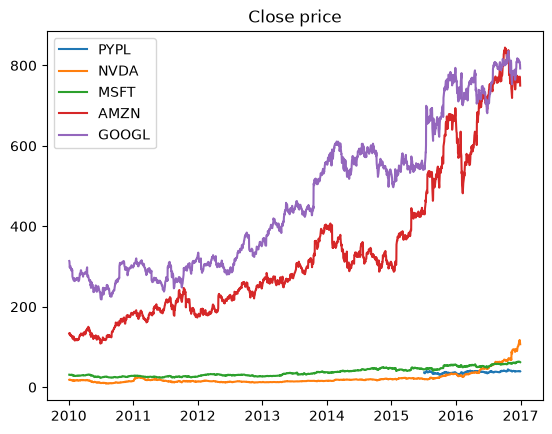

In [13]:
for s in tickers:
    d=prices[prices.symbol ==s]
    plt.plot(d.date,d.close,label=s)
plt.title("Close price")
plt.legend()
plt.savefig("figures/close_pricee.png", dpi=150, bbox_inches="tight")
plt.show()

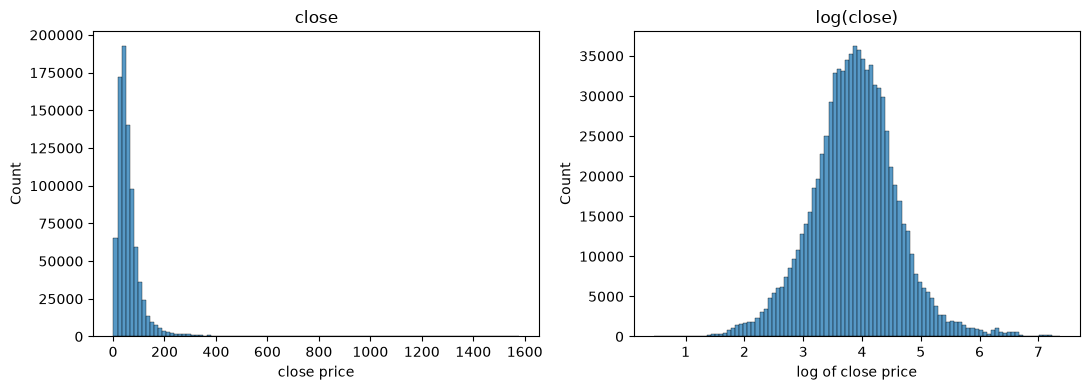

In [14]:
fig,ax = plt.subplots(1,2,figsize=(11,4))
sns.histplot(prices.close, bins=100, ax=ax[0])
ax[0].set(title="close", xlabel="close price")
sns.histplot(np.log(prices.close), bins=100, ax = ax[1])
ax[1].set(title="log(close)",xlabel="log of close price")
plt.tight_layout()
plt.savefig("figures/close_dist.png",dpi=150, bbox_inches="tight")
plt.show()

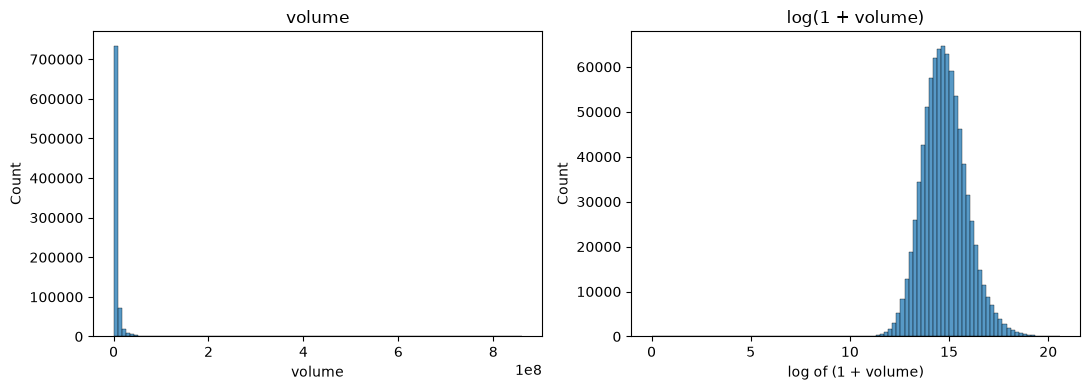

In [15]:
# distribution of the volume (raw and log)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(prices.volume, bins=100, ax=ax[0])
ax[0].set(title="volume", xlabel="volume")
sns.histplot(np.log1p(prices.volume), bins=100, ax=ax[1])
ax[1].set(title="log(1 + volume)", xlabel="log of (1 + volume)")
plt.tight_layout()
plt.savefig("figures/volume_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# daily return of each company
prices = prices.sort_values(["symbol", "date"])
prices["ret_1"] = prices.groupby("symbol")["close"].pct_change() #computes (today − yesterday) / yesterday
print(prices["ret_1"].describe())

count    850763.000000
mean          0.000592
std           0.018127
min          -0.618934
25%          -0.007821
50%           0.000570
75%           0.009051
max           2.096103
Name: ret_1, dtype: float64


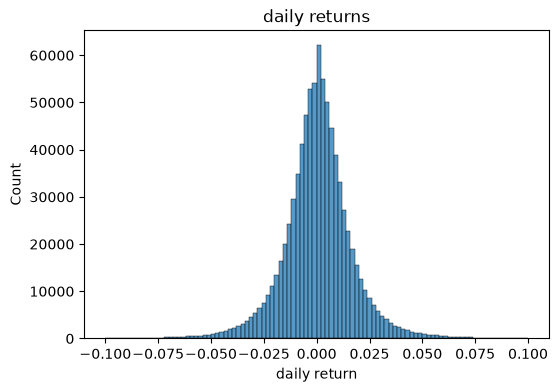

In [17]:
# distribution of the daily returns
plt.figure(figsize=(6, 4))
sns.histplot(prices["ret_1"].dropna(), bins=100, binrange=(-0.1, 0.1))
plt.title("daily returns")
plt.xlabel("daily return")
plt.savefig("figures/returns_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
print("duplicate (date, symbol):", prices.duplicated(["date", "symbol"]).sum())

duplicate (date, symbol): 0


In [19]:
print("high below open/close:", (prices.high < prices[["open", "close"]].max(axis=1)).sum())
print("low above open/close:", (prices.low > prices[["open", "close"]].min(axis=1)).sum())

high below open/close: 0
low above open/close: 0


In [20]:
n_days = prices.groupby("symbol").size()
print(n_days.describe())

count     501.000000
mean     1699.129741
std       253.731238
min       126.000000
25%      1762.000000
50%      1762.000000
75%      1762.000000
max      1762.000000
dtype: float64


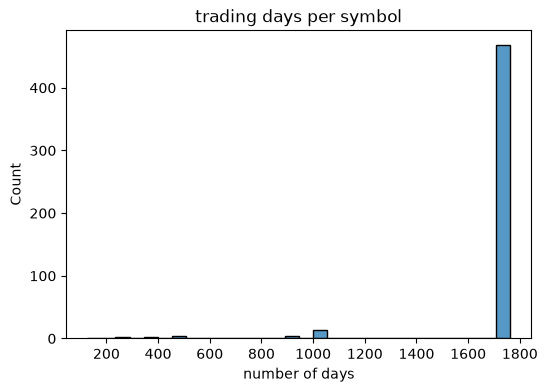

In [21]:
plt.figure(figsize=(6, 4))
sns.histplot(n_days, bins=30)
plt.title("trading days per symbol")
plt.xlabel("number of days")
plt.savefig("figures/days_per_symbol.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
prices["target"] = prices.groupby("symbol")["close"].shift(-1)

In [23]:
# features
prices["ret_5"] = prices.groupby("symbol")["close"].pct_change(5)
prices["range"] = (prices["high"] - prices["low"]) / prices["close"]
prices["ma5_ratio"] = prices.groupby("symbol")["close"].transform(lambda s: s.rolling(5).mean()) / prices["close"]
prices["log_vol"] = np.log1p(prices["volume"])

In [24]:
print(prices.shape)
prices = prices.dropna()
print(prices.shape)
print(prices[["symbol", "date", "close", "target"]].head())

(851264, 13)
(848258, 13)
     symbol       date      close     target
2590      A 2010-01-11  22.045780  21.781117
3058      A 2010-01-12  21.781117  21.952789
3526      A 2010-01-13  21.952789  22.281832
3994      A 2010-01-14  22.281832  21.766810
4462      A 2010-01-15  21.766810  22.031474


In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
feats = ["open", "high", "low", "close", "log_vol", "ret_1", "ret_5", "range", "ma5_ratio"]

In [27]:
prices = prices.sort_values("date")
cut = prices["date"].iloc[int(0.8 * len(prices))]
train = prices[prices["date"] <= cut]
test = prices[prices["date"] > cut]
print("cut date:", cut, "| train:", len(train), "| test:", len(test))

cut date: 2015-08-26 00:00:00 | train: 678834 | test: 169424


In [28]:
X_train, y_train = train[feats].values, train[["target"]].values
X_test, y_test = test[feats].values, test[["target"]].values

In [29]:
# standardize (fit on the training set only)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [30]:
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

In [31]:
print(X_train.mean(axis=0).round(2))
print(X_test.mean(axis=0).round(2))

[-0.  0. -0.  0.  0. -0. -0.  0. -0.]
[ 0.37  0.37  0.36  0.37 -0.05 -0.   -0.01  0.09  0.01]


In [32]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

#dataset definition
class StockDataset(Dataset):
        #load the dataset
        def __init__(self,x,y):
                self.x = x.astype('float32')
                self.y = y.astype('float32')
        def __len__(self):
            return(len(self.x))
        def __getitem__(self,idx):
            return [self.x[idx], self.y[idx]]
def prepare_data(X_train,y_train,X_test,y_test):
    train_dl=DataLoader(StockDataset(X_train,y_train),batch_size=1024,shuffle=True)
    test_dl=DataLoader(StockDataset(X_test,y_test), batch_size=4096,shuffle=False)
    return train_dl, test_dl

In [33]:
train_dl,test_dl=prepare_data(X_train,y_train, X_test,y_test)
print(len(train_dl.dataset),len(test_dl.dataset))


678834 169424


In [34]:
inputs,targets=next(iter(train_dl))
print(inputs.shape,targets.shape)

torch.Size([1024, 9]) torch.Size([1024, 1])


In [35]:
from torch.nn import Linear
from torch.nn import ReLU
from torch.nn import Module
from torch.nn.init import kaiming_uniform_
from torch.nn.init import xavier_uniform_
'''
# model definition
class MLP(Module):
    # define model elements
    def __init__(self, n_inputs, n_hidden1=64, n_hidden2=32):
        super(MLP, self).__init__()
        # input to first hidden layer
        self.hidden1 = Linear(n_inputs, n_hidden1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.act1 = ReLU()
        # second hidden layer
        self.hidden2 = Linear(n_hidden1, n_hidden2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.act2 = ReLU()
        # third hidden layer and output
        self.hidden3 = Linear(n_hidden2, 1)
        xavier_uniform_(self.hidden3.weight)

    # forward propagate input
    def forward(self, X):
        # input to first hidden layer
        X = self.hidden1(X)
        X = self.act1(X)
        # second hidden layer
        X = self.hidden2(X)
        X = self.act2(X)
        # third hidden layer and output
        X = self.hidden3(X)
        return X
'''
#replaced for regularization
from torch.nn import Dropout
from torch.nn import BatchNorm1d
from torch.nn import Identity

# model definition
class MLP(Module):
    # define model elements
    def __init__(self, n_inputs, n_hidden1=64, n_hidden2=32, p_drop=0.0, use_bn=False):
        super(MLP, self).__init__()
        # input to first hidden layer
        self.hidden1 = Linear(n_inputs, n_hidden1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.bn1 = BatchNorm1d(n_hidden1) if use_bn else Identity()
        self.act1 = ReLU()
        self.drop1 = Dropout(p_drop)
        # second hidden layer
        self.hidden2 = Linear(n_hidden1, n_hidden2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.bn2 = BatchNorm1d(n_hidden2) if use_bn else Identity()
        self.act2 = ReLU()
        self.drop2 = Dropout(p_drop)
        # third hidden layer and output
        self.hidden3 = Linear(n_hidden2, 1)
        xavier_uniform_(self.hidden3.weight)

    # forward propagate input
    def forward(self, X):
        # input to first hidden layer
        X = self.hidden1(X)
        X = self.bn1(X)
        X = self.act1(X)
        X = self.drop1(X)
        # second hidden layer
        X = self.hidden2(X)
        X = self.bn2(X)
        X = self.act2(X)
        X = self.drop2(X)
        # third hidden layer and output
        X = self.hidden3(X)
        return X
# define the network
model = MLP(9)
print(model)
print(sum(p.numel() for p in model.parameters()))

# one forward pass on the batch from before
yhat = model(inputs)
print(yhat.shape)

MLP(
  (hidden1): Linear(in_features=9, out_features=64, bias=True)
  (bn1): Identity()
  (act1): ReLU()
  (drop1): Dropout(p=0.0, inplace=False)
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): Identity()
  (act2): ReLU()
  (drop2): Dropout(p=0.0, inplace=False)
  (hidden3): Linear(in_features=32, out_features=1, bias=True)
)
2753
torch.Size([1024, 1])


In [36]:
from sklearn.metrics import mean_squared_error
from numpy import sqrt 
from numpy import vstack
from torch.optim import SGD
from torch.nn import MSELoss
from tqdm import tqdm

def accuracy_within(actuals, predictions, tol=0.01):
    a=sc_y.inverse_transform(actuals)
    p=sc_y.inverse_transform(predictions)
    return np.mean(np.abs(p-a)/a<tol)
def evaluate_model(dl,model):
    model.eval()
    predictions,actuals=list(),list()
    with torch.no_grad():
        for i, (inputs,targets) in enumerate(dl):
            yhat=model(inputs)
            yhat=yhat.numpy()
            actual=targets.numpy()
            actual=actual.reshape((len(actual),1))
            #store
            predictions.append(yhat)
            actuals.append(actual)
    predictions,actuals = vstack(predictions),vstack(actuals)
    mse=mean_squared_error(actuals,predictions)
    acc= accuracy_within(actuals,predictions)
    return mse,acc

'''
def train_model(train_dl, test_dl, model, epochs=20, lr=0.01):
    criterion = MSELoss()
    optimizer = SGD(model.parameters(), lr=lr, momentum=0.9)
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in tqdm(range(epochs), desc='Training Epochs'):
        model.train()
        for batch, (inputs, targets) in enumerate(train_dl):
            optimizer.zero_grad()
            yhat = model(inputs)
            loss = criterion(yhat, targets)
            loss.backward()
            optimizer.step()
        # evaluate on the train and test sets after each epoch
        train_loss, train_acc = evaluate_model(train_dl, model)
        test_loss, test_acc = evaluate_model(test_dl, model)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        print('Epoch %03d | Train loss: %.5f, acc: %.3f | Test loss: %.5f, acc: %.3f'
              % (epoch+1, train_loss, train_acc, test_loss, test_acc))
    return history
    '''
def train_model(train_dl, test_dl, model, epochs=20, lr=0.01, optimizer_class=SGD, weight_decay=0.0):
    criterion = MSELoss()
    if optimizer_class == SGD:
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        optimizer = optimizer_class(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in tqdm(range(epochs), desc='Training Epochs'):
        model.train()
        for batch, (inputs, targets) in enumerate(train_dl):
            optimizer.zero_grad()
            yhat = model(inputs)
            loss = criterion(yhat, targets)
            loss.backward()
            optimizer.step()
        # evaluate on the train and test sets after each epoch
        train_loss, train_acc = evaluate_model(train_dl, model)
        test_loss, test_acc = evaluate_model(test_dl, model)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        print('Epoch %03d | Train loss: %.5f, acc: %.3f | Test loss: %.5f, acc: %.3f'
              % (epoch+1, train_loss, train_acc, test_loss, test_acc))
    return history

def plot_history(history, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history['train_loss'], label='train')
    ax[0].plot(history['test_loss'], label='test')
    ax[0].set(title='Loss / Epochs', xlabel='epoch', ylabel='MSE (standardized)')
    ax[0].legend()
    ax[1].plot(history['train_acc'], label='train')
    ax[1].plot(history['test_acc'], label='test')
    ax[1].axhline(acc_base, color='gray', linestyle='--', label='baseline (test)')
    ax[1].set(title='Accuracy / Epochs', xlabel='epoch', ylabel='accuracy (within 1%)')
    ax[1].legend()
    plt.tight_layout()
    plt.savefig("figures/%s_curves.png" % name, dpi=150, bbox_inches="tight")
    plt.show()

In [37]:
# naive baseline: tomorrow's close = today's close
rmse_base = sqrt(mean_squared_error(test["target"], test["close"]))
acc_base = np.mean(np.abs(test["close"] - test["target"]) / test["target"] < 0.01)
print('Baseline RMSE: %.3f, accuracy: %.3f' % (rmse_base, acc_base))

Baseline RMSE: 2.179, accuracy: 0.553


In [45]:
# train the model
torch.manual_seed(1729)
model = MLP(9)
history = train_model(train_dl, test_dl, model, epochs=20)

Training Epochs:   5%|███▏                                                            | 1/20 [00:08<02:44,  8.66s/it]

Epoch 001 | Train loss: 0.00234, acc: 0.183 | Test loss: 0.00362, acc: 0.220


Training Epochs:  10%|██████▍                                                         | 2/20 [00:16<02:28,  8.26s/it]

Epoch 002 | Train loss: 0.00168, acc: 0.214 | Test loss: 0.00271, acc: 0.256


Training Epochs:  15%|█████████▌                                                      | 3/20 [00:29<02:53, 10.18s/it]

...

Epoch 018 | Train loss: 0.00125, acc: 0.292 | Test loss: 0.00268, acc: 0.307


Training Epochs:  95%|███████████████████████████████████████████████████████████▊   | 19/20 [02:55<00:08,  8.51s/it]

Epoch 019 | Train loss: 0.00105, acc: 0.310 | Test loss: 0.00214, acc: 0.336


Training Epochs: 100%|███████████████████████████████████████████████████████████████| 20/20 [03:01<00:00,  9.10s/it]

Epoch 020 | Train loss: 0.00086, acc: 0.323 | Test loss: 0.00162, acc: 0.358


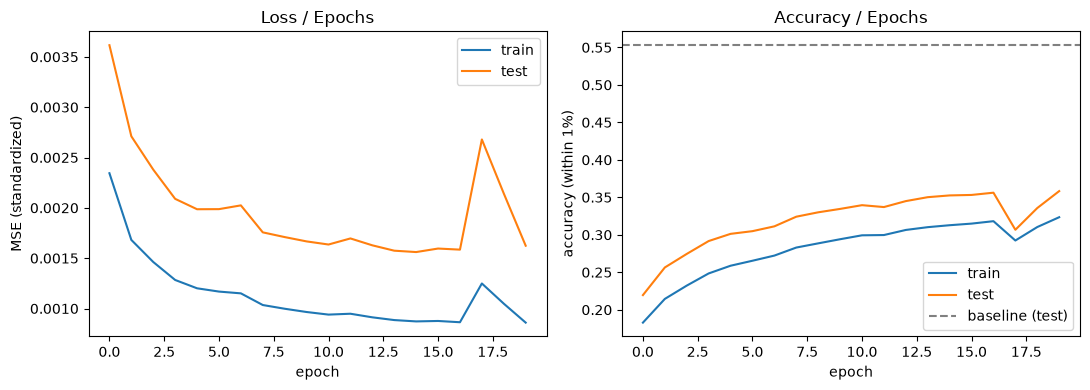

Test RMSE: 2.656, accuracy: 0.358
Baseline RMSE: 2.179, accuracy: 0.553


In [51]:
# plot loss and accuracy per epoch
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], label='train')
ax[0].plot(history['test_loss'], label='test')
ax[0].set(title='Loss / Epochs', xlabel='epoch', ylabel='MSE (standardized)')
ax[0].legend()
ax[1].plot(history['train_acc'], label='train')
ax[1].plot(history['test_acc'], label='test')
ax[1].axhline(acc_base, color='gray', linestyle='--', label='baseline (test)')
ax[1].set(title='Accuracy / Epochs', xlabel='epoch', ylabel='accuracy (within 1%)')
ax[1].legend()
plt.tight_layout()
plt.savefig("figures/mlp1_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# final results on the test set (in dollars)
mse, acc = evaluate_model(test_dl, model)
print('Test RMSE: %.3f, accuracy: %.3f' % (sqrt(mse) * sc_y.scale_[0], acc))
print('Baseline RMSE: %.3f, accuracy: %.3f' % (rmse_base, acc_base))

In [50]:
# Choosing the best hyper param for an efficient modelusing Grisearch 

from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit
from torch.optim import Adam

# subsample of the training set (every 7th row keeps the date order)
X_sub = X_train[::7].astype('float32')
y_sub = y_train[::7].astype('float32')
print(X_sub.shape, y_sub.shape)

# wrap the MLP so sklearn can use it
net = NeuralNetRegressor(
    module=MLP,
    module__n_inputs=9,
    criterion=MSELoss,
    batch_size=1024,
    train_split=None,
    verbose=0,
)

# hyper-parameters to try
param_grid = [
    {'optimizer': [SGD], 'optimizer__momentum': [0.9], 'lr': [0.01, 0.001],
     'module__n_hidden1': [32, 64], 'max_epochs': [10, 20]},
    {'optimizer': [Adam], 'lr': [0.01, 0.001],
     'module__n_hidden1': [32, 64], 'max_epochs': [10, 20]},
]

gs = GridSearchCV(net, param_grid, cv=TimeSeriesSplit(n_splits=3),
                  scoring='neg_mean_squared_error', verbose=2)


(96977, 9) (96977, 1)


In [ ]:
torch.manual_seed(1729)
gs.fit(X_sub, y_sub)
print('Best parameters:', gs.best_params_)
print('Best score (negative MSE):', gs.best_score_)

# all the results, best first
results = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
results = results.sort_values('mean_test_score', ascending=False)
os.makedirs("results", exist_ok=True)
results.to_csv("results/gridsearch.csv", index=False)
print(results.head(8))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   1.3s
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   3.0s
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   7.1s
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=64, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   1.7s
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=64, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   4.5s
[CV] END lr=0.01, max_epochs=10, module__n_hidden1=64, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   4.5s
[CV] END lr=0.01, max_epochs=20, module__n_hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, opt

In [ ]:
# second round: Adam only, around the best values
param_grid2 = {
    'optimizer': [Adam],
    'lr': [0.003, 0.01, 0.03],
    'max_epochs': [20, 40],
    'module__n_hidden1': [64, 128],
}

gs2 = GridSearchCV(net, param_grid2, cv=TimeSeriesSplit(n_splits=3),
                   scoring='neg_mean_squared_error', verbose=2)
torch.manual_seed(1729)
gs2.fit(X_sub, y_sub)
print('Best parameters:', gs2.best_params_)
print('Best score (negative MSE):', gs2.best_score_)

# all the results, best first
pd.set_option('display.max_colwidth', None)
results2 = pd.DataFrame(gs2.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
results2 = results2.sort_values('mean_test_score', ascending=False)
results2.to_csv("results/gridsearch2.csv", index=False)
print(results2)

In [38]:
# train the best model on the full training set
torch.manual_seed(1729)
model2 = MLP(9, n_hidden1=64, n_hidden2=32)
history2 = train_model(train_dl, test_dl, model2, epochs=40, lr=0.01, optimizer_class=Adam)
pd.DataFrame(history2).to_csv("results/mlp2_history.csv", index=False)

Training Epochs:   0%|                                                                        | 0/40 [00:00<?, ?it/s]/home/vernical/Desktop/MST-SIBD/S3/deep-learning/assignment-1/DeepLearning-Lab1/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Training Epochs:   2%|█▌                                                              | 1/40 [00:07<05:05,  7.84s/it]

Epoch 001 | Train loss: 0.00121, acc: 0.256 | Test loss: 0.00222, acc: 0.283


Training Epochs:   5%|███▏                                                            | 2/40 [00:13<04:14,  6.69s/it]

Epoch 002 | Train loss: 0.00074, acc: 0.346 | Test loss: 0.00144, acc: 0.380


Training Epochs:   8%|████▊                                                           | 3/40 [00:21<04:25,  7.18s/it]

...

Epoch 038 | Train loss: 0.00055, acc: 0.523 | Test loss: 0.00118, acc: 0.515


Training Epochs:  98%|█████████████████████████████████████████████████████████████▍ | 39/40 [06:12<00:08,  8.74s/it]

Epoch 039 | Train loss: 0.00127, acc: 0.470 | Test loss: 0.00321, acc: 0.428


Training Epochs: 100%|███████████████████████████████████████████████████████████████| 40/40 [06:24<00:00,  9.62s/it]

Epoch 040 | Train loss: 0.00053, acc: 0.539 | Test loss: 0.00116, acc: 0.529


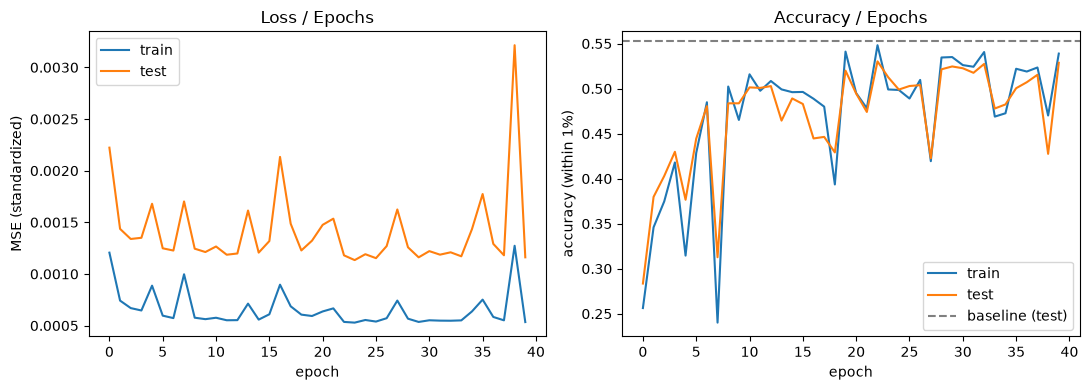

Test RMSE: 2.246, accuracy: 0.529
Baseline RMSE: 2.179, accuracy: 0.553


In [61]:
plot_history(history2, 'mlp2')

mse, acc = evaluate_model(test_dl, model2)
print('Test RMSE: %.3f, accuracy: %.3f' % (sqrt(mse) * sc_y.scale_[0], acc))
print('Baseline RMSE: %.3f, accuracy: %.3f' % (rmse_base, acc_base))


In [ ]:
from torch.nn import Dropout
from torch.nn import BatchNorm1d
from torch.nn import Identity
# model definition
class MLP(Module):
    # define model elements
    def __init__(self, n_inputs, n_hidden1=64, n_hidden2=32, p_drop=0.0, use_bn=False):
        super(MLP, self).__init__()
        # input to first hidden layer
        self.hidden1 = Linear(n_inputs, n_hidden1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.bn1 = BatchNorm1d(n_hidden1) if use_bn else Identity()
        self.act1 = ReLU()
        self.drop1 = Dropout(p_drop)
        # second hidden layer
        self.hidden2 = Linear(n_hidden1, n_hidden2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.bn2 = BatchNorm1d(n_hidden2) if use_bn else Identity()
        self.act2 = ReLU()
        self.drop2 = Dropout(p_drop)
        # third hidden layer and output
        self.hidden3 = Linear(n_hidden2, 1)
        xavier_uniform_(self.hidden3.weight)
    # forward propagate input
    def forward(self, X):
        # input to first hidden layer
        X = self.hidden1(X)
        X = self.bn1(X)
        X = self.act1(X)
        X = self.drop1(X)
        # second hidden layer
        X = self.hidden2(X)
        X = self.bn2(X)
        X = self.act2(X)
        X = self.drop2(X)
        # third hidden layer and output
        X = self.hidden3(X)
        return X

In [ ]:
# train the best model on the full training set
from torch.optim import Adam
torch.manual_seed(1729)
model2 = MLP(9, n_hidden1=64, n_hidden2=32)
history2 = train_model(train_dl, test_dl, model2, epochs=40, lr=0.01, optimizer_class=Adam)
os.makedirs("results", exist_ok=True)
pd.DataFrame(history2).to_csv("results/mlp2_history.csv", index=False)

In [2]:
configs = {
    'L2 (weight decay 1e-4)': dict(weight_decay=1e-4),
    'Dropout (p=0.2)': dict(p_drop=0.2),
    'Batch normalization': dict(use_bn=True),
    'Dropout + L2': dict(p_drop=0.2, weight_decay=1e-4),
}
scale = sc_y.scale_[0]
histories = {'No regularization (best model)': history2}
models = {'No regularization (best model)': model2}

for name, cfg in configs.items():
    print('=====', name)
    torch.manual_seed(1729)
    m = MLP(9, n_hidden1=64, n_hidden2=32,
            p_drop=cfg.get('p_drop', 0.0), use_bn=cfg.get('use_bn', False))
    histories[name] = train_model(train_dl, test_dl, m, epochs=40, lr=0.01, optimizer_class=Adam,
                                  weight_decay=cfg.get('weight_decay', 0.0))
    models[name] = m

rows = []
for name, m in models.items():
    mse_tr, acc_tr = evaluate_model(train_dl, m)
    mse_te, acc_te = evaluate_model(test_dl, m)
    rows.append({'model': name,
                 'train acc': round(acc_tr, 3), 'test acc': round(acc_te, 3),
                 'test acc (mean last 5 epochs)': round(np.mean(histories[name]['test_acc'][-5:]), 3),
                 'test RMSE ($)': round(sqrt(mse_te) * scale, 3)})
table = pd.DataFrame(rows)
table.to_csv("results/regularization.csv", index=False)
print(table)

NameError: name 'sc_y' is not defined